# Neural population analysis — Hakim BMI packets

First-pass **neural** analyses that prototype the population-dynamics measures in the proposal
(`proposal.docx`) on the real BMI dataset. Companion to `first_pass_analysis.ipynb` (behavior +
first-pass PCA), which is left untouched.

**How this notebook is organised.** Reusable math/data tools live in
`utilities/neural_analysis_utils.py` (imported as `na`). The *analysis flow and all plotting live
here, in the open*, so everything is easy to change and extend. To avoid reloading each day's neural
data once per figure, all per-day metrics are computed in **one pass per mouse** (`compute_mouse`,
below) into tidy tables that are cached to `output/<mouse>/neural_analysis/`; the plotting sections
just visualise those tables. The per-day compute functions are short and visible — edit them freely.

**What it does (per animal):**
1. Effective **dimensionality** (matched participation ratio) for 4 conditions — correct, incorrect,
   baseline, reward-consumption — per full day.
2. **Trajectory length** and length-deconfounded **trajectory variability** for correct trials.
3. The same metrics in **sliding windows** within each day, overlaid across days, and **correlated
   with reward rate** (raw + smoothed).
4. **Manifold alignment** (principal angles) of the correct-trial subspace across days.
5. **Cross-validated Factor-Analysis** dimensionality (the proposal's model-selection method) as an
   optional diagnostic (`RUN_FA_CV`).
6. For `mouse_0403L` (has a remapping phase): **intuitive vs new decoder axis** comparison across
   days, and the *one-vs-two-trajectory* question.

**Key modelling choices (verified on the data; change in the config cell):**
- Neural data are `(neurons, time)`, 30 Hz, non-negative rates → **smooth** (Gaussian, ~166 ms) then
  **z-score** per neuron. Raw 30 Hz data is noise-dominated (participation ratio ~170); smoothing
  concentrates variance into an interpretable range (~50).
- **Correct trials:** `[trialStart, trialEnd]` (variable length; reward is delivered ~0.4 s *after*
  trialEnd, so this is free of reward-consumption contamination). PCA/FA use the `N × ΣT` matrix, so
  unequal trial lengths are fine.
- **Incorrect trials:** fixed `[trialStart, trialStart+20 s]` (20 s = max trial duration here).
  **Baseline:** frames with no trial start within ±10 s. **Reward consumption:** `[reward, reward+7 s]`.
- Dimensionality is **sample-size dependent**, so comparisons use a **matched sample count**
  (the proposal's "matched trial counts"). Participation ratio is the fast comparative metric; FA-CV
  is the rigorous model-selection cross-check (its held-out likelihood keeps rising to the grid edge
  here — the correct-trial activity is genuinely high-dimensional).
- Decoder/factor **weights are ignored** (unreliable). `factor_to_use` is used only as a categorical
  axis label (2 = intuitive, 3 = new).

In [2]:
%matplotlib inline
import sys, os, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr

# --- reusable tools (utilities/neural_analysis_utils.py) ---
REPO = Path.cwd()
sys.path.insert(0, str(REPO / "utilities"))
import importlib, neural_analysis_utils as na
importlib.reload(na)

import richfile as rfs
na.register_richfile_types(rfs)

try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(x, **k): return x

# ============================ CONFIG ============================
SR = 30                              # Hz
DATA_ROOT = Path(r"C:\Data\datasets\bmi_packets\bmi_packets")
OUTPUT_ROOT = REPO / "output"
MICE = ["mouse_0403L", "mouse_0322R", "mouse_0403R", "mouse_0916N"]
MAX_DAYS_PER_PHASE = None            # cap days per phase (e.g. 5) for a quick test run; None = all

# preprocessing
SMOOTH_SIGMA_FRAMES = 5              # ~166 ms Gaussian; 0 disables
K_PC = 10                            # fixed PCA subspace for trajectory & alignment

# condition definitions
INCORRECT_WINDOW_SEC = 20.0
BASELINE_EXCLUDE_SEC = 10.0
BASELINE_MIN_LEN_SEC = 2.0
REWARD_CONSUME_SEC = 5.0             # try 5 / 10 here
CONDITIONS = ["correct", "incorrect", "baseline", "reward_consume"]

# dimensionality (matched participation ratio = primary comparative metric)
MATCHED_N_SAMPLES_DAY = 3000
MATCHED_N_SAMPLES_WIN = 1500
MATCHED_N_BOOT = 8
MIN_TRIALS = 5                       # skip a condition / window with fewer trials

# trajectory / windows
N_RESAMPLE = 50
WIN_SEC = 150.0
STEP_SEC = 60.0
REWARD_SMOOTH_WIN = 5                # windows, for smoothed reward-rate trace

# Factor-Analysis CV (proposal's method) — slow diagnostic, off by default
RUN_FA_CV = False
FA_CONDITIONS = ["correct"]
FA_DIMS = [2, 3, 5, 8, 12, 20, 35, 50]
FA_SAMPLE_CAP = 5000
FA_FOLDS = 4
FA_N_JOBS = -1

#corecting the day zero for the mice that have a different day zero than the first day of recording. This is important for aligning the data across mice.
DAY_ZERO_ADJUSTMENT = {}
DAY_ZERO_ADJUSTMENT['mouse_0322R'] = '20230502'
DAY_ZERO_ADJUSTMENT['mouse_0403L'] = None
DAY_ZERO_ADJUSTMENT['mouse_0403R'] = None
DAY_ZERO_ADJUSTMENT['mouse_0916N'] = None

USE_CACHE = True                     # reuse saved metric tables if present
# Cached table filenames embed the parameters that affect them, so changing a
# parameter automatically recomputes rather than silently loading stale results.
PARAM_TAG = f"s{SMOOTH_SIGMA_FRAMES}_k{K_PC}_m{MATCHED_N_SAMPLES_DAY}w{MATCHED_N_SAMPLES_WIN}_rc{int(REWARD_CONSUME_SEC)}_win{int(WIN_SEC)}-{int(STEP_SEC)}"
sns.set_context("notebook")
print("config loaded; mice:", MICE, "| RUN_FA_CV =", RUN_FA_CV, "| tag:", PARAM_TAG)

config loaded; mice: ['mouse_0403L', 'mouse_0322R', 'mouse_0403R', 'mouse_0916N'] | RUN_FA_CV = False | tag: s5_k10_m3000w1500_rc5_win150-60


## 1 · Data access & phase splitting

`load_mouse` opens a mouse, finds day-0 (spontaneous), and splits days into the **stable-control**
phase (single decoder factor) and the **remapping** phase (two factors: intuitive + new).
`preprocess_day` loads one day and returns the smoothed/z-scored `(N, T)` session plus its trials and
active-reward frames. `build_conditions` turns those into the four condition interval-lists — edit the
condition definitions here to explore alternatives.

In [3]:
from dataclasses import dataclass

@dataclass
class Mouse:
    name: str; r: object; days: list; day0: str; day0_idx: int
    stable_days: list; remap_days: list; factors_per_day: dict; out: Path

def load_mouse(name):
    r = na.open_mouse(rfs, DATA_ROOT, name)
    days = na.get_day_list(r)
    if name in DAY_ZERO_ADJUSTMENT and DAY_ZERO_ADJUSTMENT[name] is not None:
        day0 = DAY_ZERO_ADJUSTMENT[name]
    else:
        day0 = r["date_day0"].load()
    day0 = str(np.asarray(day0).ravel()[0]) if not isinstance(day0, str) else day0
    day0_idx = days.index(day0) if day0 in days else 0
    fpd = {}
    for d in days:
        tr = na.get_true_bmi_trials(na.get_trials_df(r, d))
        fpd[d] = np.unique(tr.factor[np.isfinite(tr.factor)])
    usable = [d for d in days[day0_idx:] if fpd[d].size >= 1]
    stable = [d for d in usable if fpd[d].size == 1]
    remap  = [d for d in usable if fpd[d].size > 1]
    if MAX_DAYS_PER_PHASE:
        stable, remap = stable[:MAX_DAYS_PER_PHASE], remap[:MAX_DAYS_PER_PHASE]
    out = OUTPUT_ROOT / name / "neural_analysis"; out.mkdir(parents=True, exist_ok=True)
    return Mouse(name, r, days, day0, day0_idx, stable, remap, fpd, out)

def preprocess_day(mo, day):
    neural = na.load_neural(mo.r, day)
    X = na.preprocess_session(neural, smooth_sigma_frames=SMOOTH_SIGMA_FRAMES, zscore=True)
    trials = na.get_true_bmi_trials(na.get_trials_df(mo.r, day))
    rew = na.get_active_reward_frames(mo.r, day)
    return X, trials, rew, X.shape[1]

def build_conditions(X, trials, reward_frames, T, *, factor=None):
    return {
        "correct":        na.correct_trial_intervals(trials, T, factor=factor),
        "incorrect":      na.incorrect_trial_intervals(trials, T, window_sec=INCORRECT_WINDOW_SEC, sr=SR, factor=factor),
        "baseline":       na.baseline_intervals(trials, T, exclude_sec=BASELINE_EXCLUDE_SEC, sr=SR, min_len_sec=BASELINE_MIN_LEN_SEC),
        "reward_consume": na.reward_consumption_intervals(reward_frames, T, dur_sec=REWARD_CONSUME_SEC, sr=SR),
    }

def n_trials_of(name, trials, factor=None):
    if name == "correct":   return int(trials.mask(success=1, factor=factor).sum())
    if name == "incorrect": return int(trials.mask(success=0, factor=factor).sum())
    return None

mice = {m: load_mouse(m) for m in MICE}
for m, mo in mice.items():
    print(f"{m:14s} days={len(mo.days):2d} day0={mo.day0} stable={len(mo.stable_days):2d} remap={len(mo.remap_days):2d}")

mouse_0403L    days=36 day0=20230703 stable=20 remap=15
mouse_0322R    days=35 day0=20230502 stable=24 remap= 0
mouse_0403R    days= 6 day0=20230703 stable= 4 remap= 0
mouse_0916N    days= 4 day0=20231023 stable= 2 remap= 0


## 2 · Single-pass per-day computation

Each day is loaded and preprocessed **once**, then all metrics are computed from it:

- **`day_dim_rows`** — effective dimensionality (matched PR + raw PR + PCs for 80/90 % variance) for
  each of the four conditions.
- **`day_trajectory`** — fits the day's fixed `K_PC` correct-trial subspace, computes trajectory
  length and length-deconfounded variability, and the subspace's alignment to a reference day.
- **`day_window_rows`** — sliding-window matched-PR, trajectory length/variability, and reward rate,
  reusing the day's subspace.
- **`day_fa_rows`** — optional FA-CV curves.

`compute_mouse` runs the pass and caches four tidy tables per mouse. The functions are intentionally
small and explicit so you can change any metric.

In [4]:
def day_dim_rows(mo, day, phase, X, trials, rew, T):
    conds = build_conditions(X, trials, rew, T)
    rows = []
    for cname in CONDITIONS:
        ivs = conds[cname]
        ns = na.n_samples(ivs)
        if ns < MATCHED_N_SAMPLES_DAY // 3:      # too little data to estimate
            continue
        Xc = na.intervals_to_matrix(X, ivs)
        spec = na.pca_spectrum(Xc)
        pr_m, pr_sd = na.participation_ratio_matched(Xc, MATCHED_N_SAMPLES_DAY, n_boot=MATCHED_N_BOOT)
        rows.append(dict(mouse=mo.name, day=day, day_from0=mo.days.index(day)-mo.day0_idx, phase=phase,
                         condition=cname, n_trials=n_trials_of(cname, trials), n_samples=ns,
                         pr_matched=pr_m, pr_matched_sd=pr_sd, pr_raw=spec.participation_ratio,
                         d80=na.dim_at_variance(spec, 0.8), d90=na.dim_at_variance(spec, 0.9)))
    return rows

def day_trajectory(mo, day, phase, X, trials, T, ref_sub):
    ivs = na.correct_trial_intervals(trials, T)
    if len(ivs) < 2:
        return None, None
    Xc = na.intervals_to_matrix(X, ivs)
    sub = na.fit_subspace(Xc, K_PC)
    trajs = [sub.project(t) for t in na.intervals_to_trajectories(X, ivs)]
    ts = na.trajectory_stats(trajs, n_resample=N_RESAMPLE)
    row = dict(mouse=mo.name, day=day, day_from0=mo.days.index(day)-mo.day0_idx, phase=phase,
               n_trials=ts.n_trials, mean_length=ts.mean_length, length_sd=ts.length_sd,
               var_raw=ts.var_raw, var_per_length=ts.var_per_length, var_per_meanpath=ts.var_per_meanpath,
               subspace_var=float(sub.explained_ratio.sum()),
               alignment_to_ref=(na.alignment_index(ref_sub, sub) if ref_sub is not None else 1.0))
    return row, sub

def day_window_rows(mo, day, phase, X, trials, rew, T, sub):
    ivs = na.correct_trial_intervals(trials, T)
    trajs = [sub.project(t) for t in na.intervals_to_trajectories(X, ivs)] if (sub is not None and ivs) else []
    starts = np.array([s for s, e in ivs]) if ivs else np.array([])
    wins = na.sliding_windows(T, win_sec=WIN_SEC, step_sec=STEP_SEC, sr=SR)
    rr = na.reward_rate_in_windows(rew, wins, sr=SR)
    rr_sm = na.smooth_series(rr, REWARD_SMOOTH_WIN)
    remap_frame = na.remapping_start_frame(trials) if phase == "remap" else None
    rows = []
    for i, w in enumerate(wins):
        ivw = na.intervals_within(ivs, w.start, w.end, min_len=SR) if ivs else []
        pr_m = np.nan
        if na.n_samples(ivw) >= MATCHED_N_SAMPLES_WIN:
            pr_m, _ = na.participation_ratio_matched(na.intervals_to_matrix(X, ivw), MATCHED_N_SAMPLES_WIN, n_boot=1)
        tlen, tvar = np.nan, np.nan
        if trajs and starts.size:
            in_w = np.where((starts >= w.start) & (starts < w.end))[0]
            if in_w.size >= MIN_TRIALS:
                tt = na.trajectory_stats([trajs[j] for j in in_w], n_resample=N_RESAMPLE)
                tlen, tvar = tt.mean_length, tt.var_per_length
        center = w.center_sec / 60.0
        rows.append(dict(mouse=mo.name, day=day, day_from0=mo.days.index(day)-mo.day0_idx, phase=phase,
                         win_idx=i, center_min=center,
                         center_min_aligned=(center - remap_frame/SR/60.0) if remap_frame is not None else np.nan,
                         pr_matched=pr_m, traj_length=tlen, traj_var=tvar,
                         reward_rate=rr[i], reward_rate_smooth=rr_sm[i]))
    return rows

def day_fa_rows(mo, day, phase, X, trials, rew, T):
    conds = build_conditions(X, trials, rew, T)
    rows = []
    for cname in FA_CONDITIONS:
        Xc = na.intervals_to_matrix(X, conds[cname])
        if Xc.shape[0] < FA_FOLDS * 5:
            continue
        fa = na.cv_fa_dimensionality(Xc, dims=FA_DIMS, n_folds=FA_FOLDS, sample_cap=FA_SAMPLE_CAP, n_jobs=FA_N_JOBS)
        for d, ll, se in zip(fa["dims"], fa["mean_ll"], fa["sem_ll"]):
            rows.append(dict(mouse=mo.name, day=day, day_from0=mo.days.index(day)-mo.day0_idx, phase=phase,
                             condition=cname, dim=int(d), mean_ll=ll, sem_ll=se,
                             best_dim=fa["best_dim"], best_is_edge=fa["best_is_edge"]))
    return rows

In [5]:
def compute_mouse(mo):
    dim_rows, traj_rows, win_rows, fa_rows = [], [], [], []
    ref_sub = None
    for day in tqdm(mo.stable_days + mo.remap_days, desc=mo.name):
        phase = "stable" if day in mo.stable_days else "remap"
        X, trials, rew, T = preprocess_day(mo, day)
        dim_rows += day_dim_rows(mo, day, phase, X, trials, rew, T)
        trow, sub = day_trajectory(mo, day, phase, X, trials, T, ref_sub)
        if trow is not None:
            traj_rows.append(trow)
            if ref_sub is None:
                ref_sub = sub               # first valid day = alignment reference
        win_rows += day_window_rows(mo, day, phase, X, trials, rew, T, sub)
        if RUN_FA_CV:
            fa_rows += day_fa_rows(mo, day, phase, X, trials, rew, T)
    return (pd.DataFrame(dim_rows), pd.DataFrame(traj_rows),
            pd.DataFrame(win_rows), pd.DataFrame(fa_rows))

def compute_or_load(mo):
    names = ["dim_table", "traj_table", "window_table", "fa_cv_table"]
    fps = [mo.out / f"{n}_{PARAM_TAG}.csv" for n in names]
    core_cached = USE_CACHE and all(fp.exists() and fp.stat().st_size > 0 for fp in fps[:3])
    fa_cached = (not RUN_FA_CV) or (fps[3].exists() and fps[3].stat().st_size > 0)
    if core_cached and fa_cached:
        dfs = [pd.read_csv(fp) if (fp.exists() and fp.stat().st_size > 0) else pd.DataFrame() for fp in fps]
        return tuple(dfs)
    dfs = compute_mouse(mo)
    for df, fp in zip(dfs, fps):
        if fp == fps[3] and not RUN_FA_CV:
            continue   # don't write an empty FA-CV cache when FA is disabled
        df.to_csv(fp, index=False)
    return dfs

_tables = {m: compute_or_load(mo) for m, mo in mice.items()}
dim_df  = pd.concat([t[0] for t in _tables.values()], ignore_index=True)
traj_df = pd.concat([t[1] for t in _tables.values()], ignore_index=True)
win_df  = pd.concat([t[2] for t in _tables.values()], ignore_index=True)
fa_df   = pd.concat([t[3] for t in _tables.values()], ignore_index=True) if RUN_FA_CV else pd.DataFrame()
print("dim", dim_df.shape, "| traj", traj_df.shape, "| win", win_df.shape, "| fa", fa_df.shape)
dim_df.head()

mouse_0403L:   0%|          | 0/35 [00:00<?, ?it/s]

mouse_0322R:   0%|          | 0/24 [00:00<?, ?it/s]

mouse_0403R:   0%|          | 0/4 [00:00<?, ?it/s]

mouse_0916N:   0%|          | 0/2 [00:00<?, ?it/s]

dim (258, 12) | traj (65, 12) | win (4070, 12) | fa (0, 0)


,mouse,day,day_from0,phase,condition,n_trials,n_samples,pr_matched,pr_matched_sd,pr_raw,d80,d90
0,mouse_0403L,20230705,1,stable,correct,223.0,27639,50.377183,1.032371,51.445359,159,240
1,mouse_0403L,20230705,1,stable,incorrect,24.0,14400,34.678486,0.840775,35.404131,100,169
2,mouse_0403L,20230705,1,stable,baseline,NaN,23684,57.706678,1.010078,58.676212,145,223
3,mouse_0403L,20230705,1,stable,reward_consume,NaN,33450,62.819381,0.757044,64.251119,160,244
4,mouse_0403L,20230706,2,stable,correct,218.0,34010,37.708986,0.670890,38.004065,169,253


## 3 · Effective dimensionality per day (matched participation ratio)

Effective dimensionality `PR = (Σλ)² / Σλ²` at a matched sample count, so days/conditions with
different amounts of data are compared fairly.

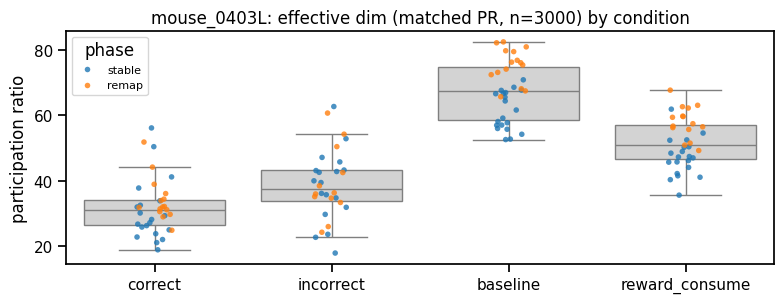

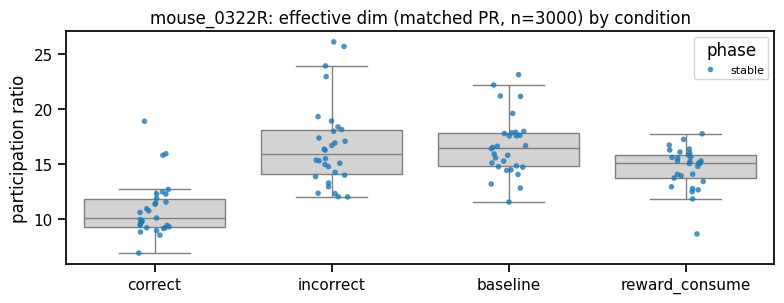

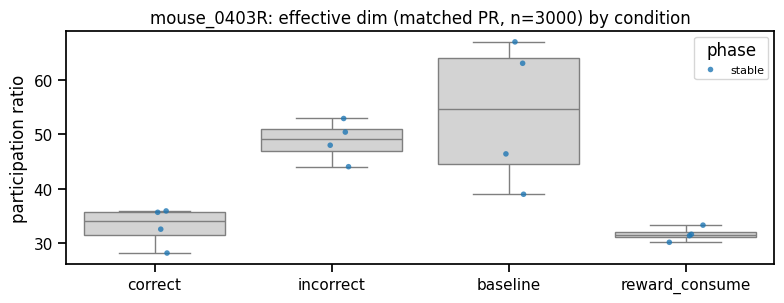

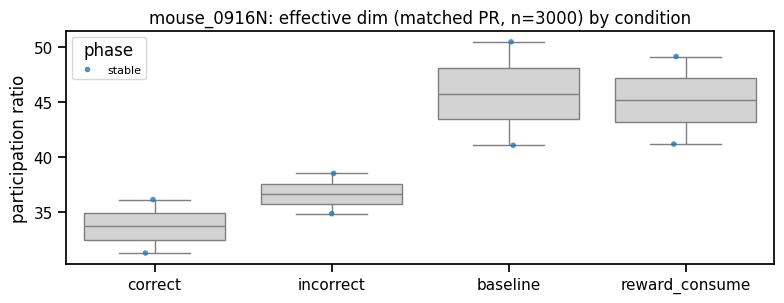

In [ ]:
for m, mo in mice.items():
    sub = dim_df[dim_df.mouse == m]
    if sub.empty: continue
    fig, ax = plt.subplots(figsize=(8, 3.2))
    sns.boxplot(data=sub, x="condition", y="pr_matched", order=CONDITIONS, color="lightgray", fliersize=0, ax=ax)
    sns.stripplot(data=sub, x="condition", y="pr_matched", order=CONDITIONS, hue="phase", size=4, alpha=0.8, ax=ax)
    ax.set(title=f"{m}: effective dim (matched PR, n={MATCHED_N_SAMPLES_DAY}) by condition",
           ylabel="participation ratio", xlabel="")
    ax.legend(title="phase", fontsize=8)
    fig.tight_layout(); fig.savefig(mo.out / f"{m}_dim_by_condition.png", dpi=150); plt.show()

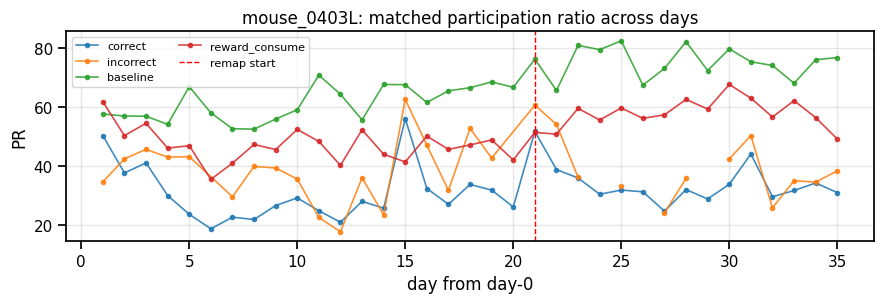

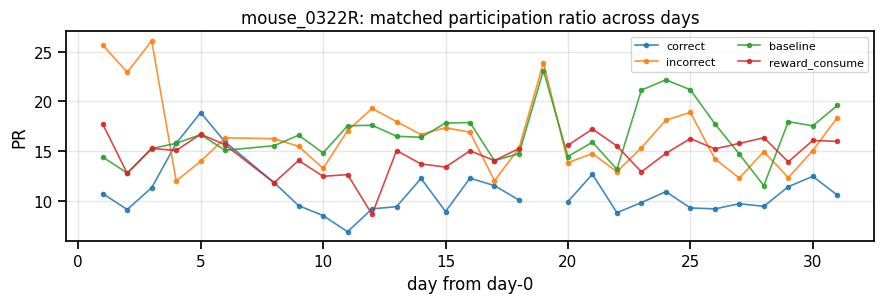

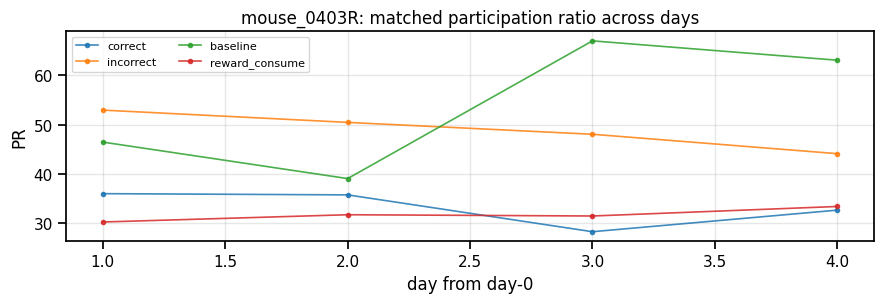

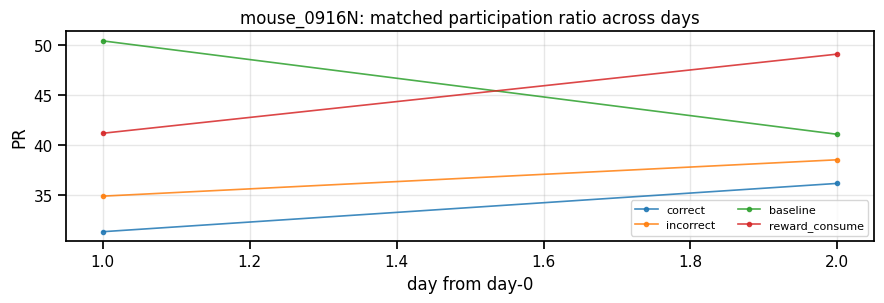

In [ ]:
for m, mo in mice.items():
    sub = dim_df[dim_df.mouse == m]
    if sub.empty: continue
    fig, ax = plt.subplots(figsize=(9, 3.2))
    for cname in CONDITIONS:
        s = sub[sub.condition == cname].sort_values("day_from0")
        if not s.empty:
            ax.plot(s.day_from0, s.pr_matched, "o-", ms=3, lw=1.2, label=cname, alpha=0.85)
    if mo.remap_days:
        ax.axvline(mo.days.index(mo.remap_days[0]) - mo.day0_idx, color="r", ls="--", lw=1, label="remap start")
    ax.set(title=f"{m}: matched participation ratio across days", xlabel="day from day-0", ylabel="PR")
    ax.legend(fontsize=8, ncol=2); ax.grid(alpha=0.3)
    fig.tight_layout(); fig.savefig(mo.out / f"{m}_dim_across_days.png", dpi=150); plt.show()

## 4 · Trajectory length & variability (correct trials)

In each day's fixed `K_PC`-dim correct-trial subspace, per correct trial: **trajectory length**
(summed Euclidean step length start→reward) and **trial-to-trial variability** (cross-trial variance
at matched normalised times). Because raw spread grows with path size, two **length-deconfounded**
versions are shown: `var_per_length` (÷ mean length²) and `var_per_meanpath` (÷ variance of the mean
trajectory).

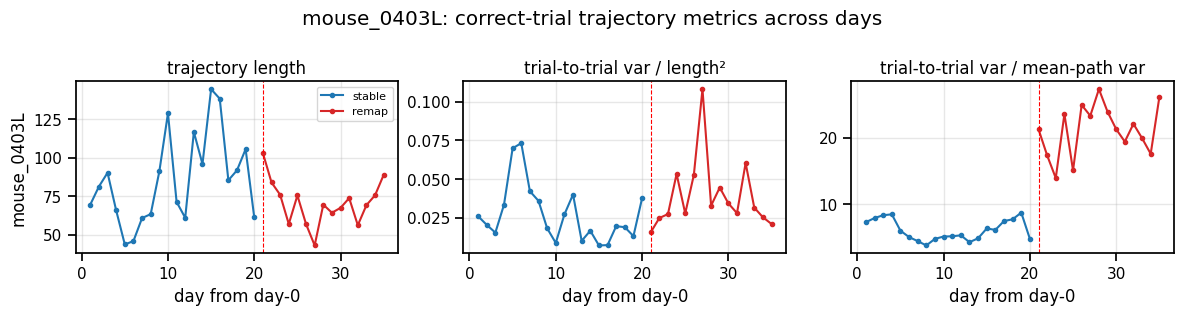

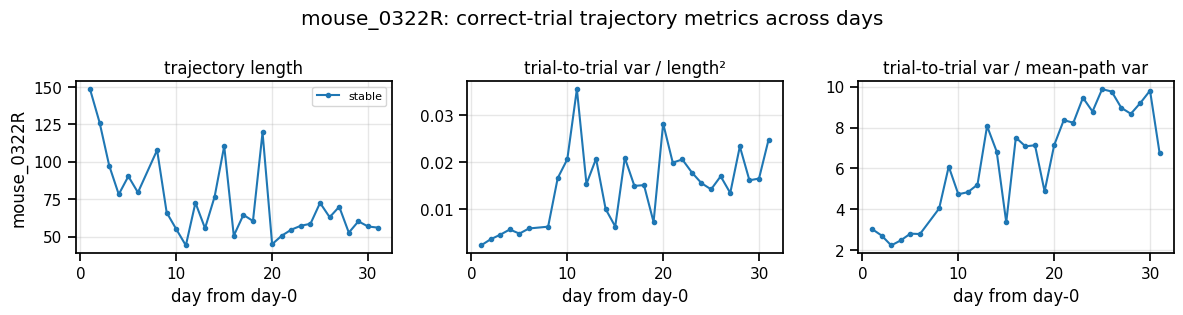

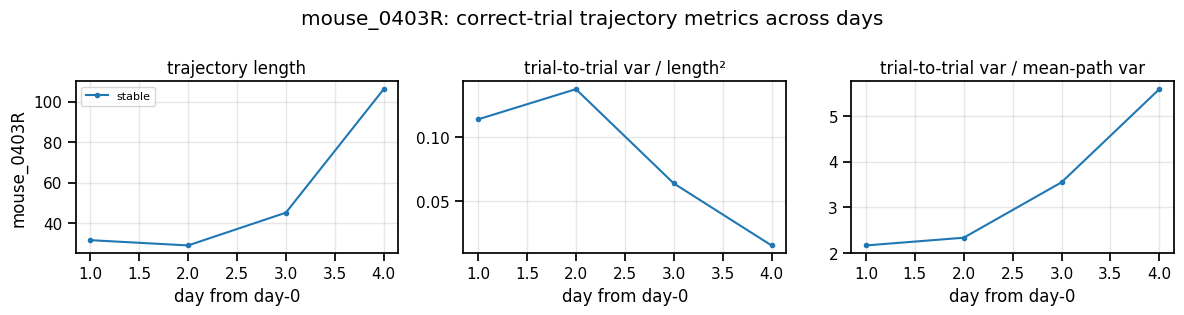

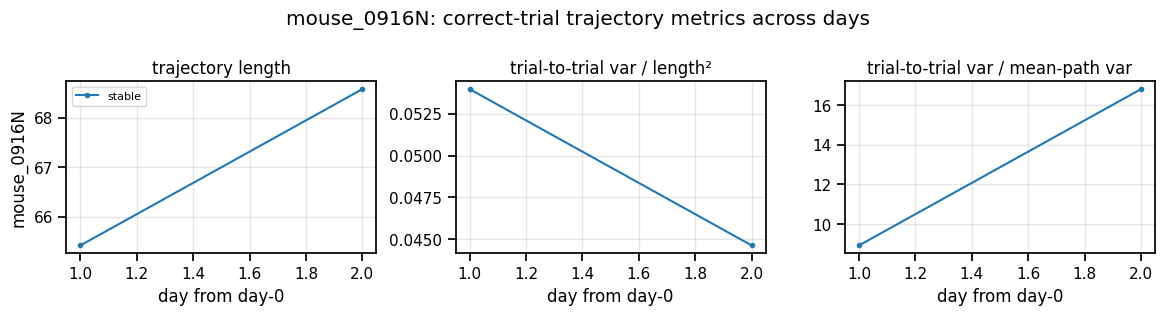

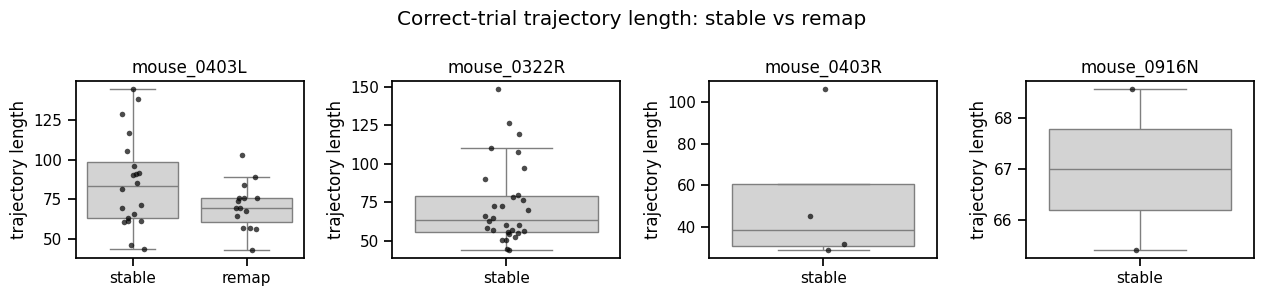

In [ ]:
metrics = [("mean_length","trajectory length"),
           ("var_per_length","trial-to-trial var / length²"),
           ("var_per_meanpath","trial-to-trial var / mean-path var")]
for m, mo in mice.items():
    sub = traj_df[traj_df.mouse == m].sort_values("day_from0")
    if sub.empty: continue
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
    for ax, (col, lab) in zip(axes, metrics):
        for ph, cc in [("stable","tab:blue"), ("remap","tab:red")]:
            s = sub[sub.phase == ph]
            if not s.empty:
                ax.plot(s.day_from0, s[col], "o-", ms=3, color=cc, label=ph)
        if mo.remap_days:
            ax.axvline(mo.days.index(mo.remap_days[0]) - mo.day0_idx, color="r", ls="--", lw=0.8)
        ax.set(title=lab, xlabel="day from day-0"); ax.grid(alpha=0.3)
    axes[0].set_ylabel(m); axes[0].legend(fontsize=8)
    fig.suptitle(f"{m}: correct-trial trajectory metrics across days")
    fig.tight_layout(); fig.savefig(mo.out / f"{m}_traj_across_days.png", dpi=150); plt.show()

# box comparison across days (per mouse)
fig, axes = plt.subplots(1, len(MICE), figsize=(3.2*len(MICE), 3), sharey=False)
if len(MICE) == 1: axes = [axes]
for ax, m in zip(axes, MICE):
    s = traj_df[traj_df.mouse == m]
    if s.empty: continue
    sns.boxplot(data=s, x="phase", y="mean_length", ax=ax, color="lightgray", fliersize=0)
    sns.stripplot(data=s, x="phase", y="mean_length", ax=ax, size=4, alpha=0.7, color="k")
    ax.set(title=m, xlabel="", ylabel="trajectory length")
fig.suptitle("Correct-trial trajectory length: stable vs remap")
fig.tight_layout(); plt.show()

## 5 · Sliding-window metrics & correlation with reward rate

Within each day: matched-PR dimensionality (fixed `MATCHED_N_SAMPLES_WIN`, so a PR–reward correlation
is not a sample-size artefact), mean trajectory length and length-deconfounded variability (using the
day's fixed correct subspace), and raw + smoothed **reward rate** per window. Then each neural measure
is correlated with reward rate (Pearson + Spearman).

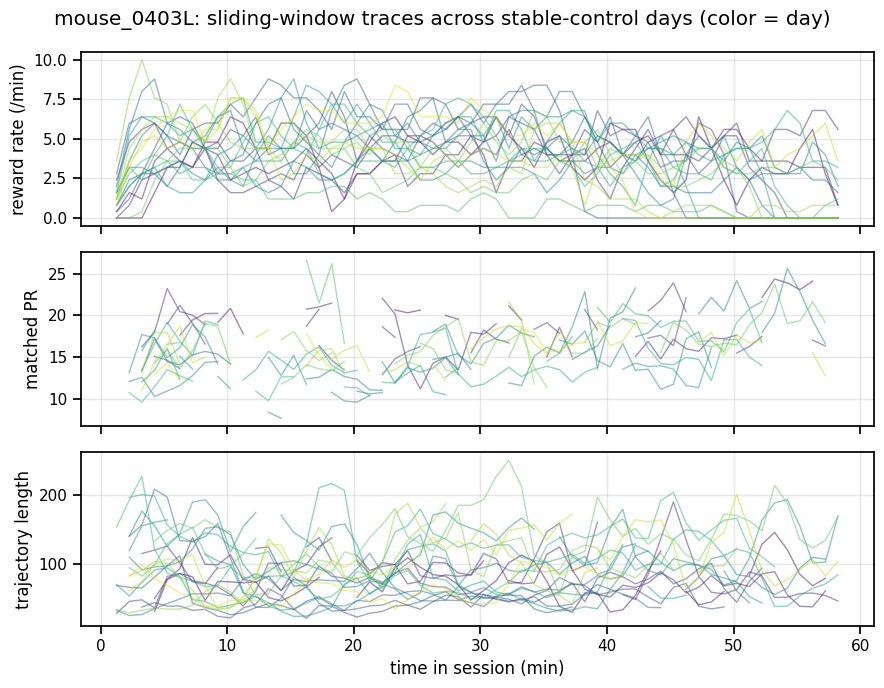

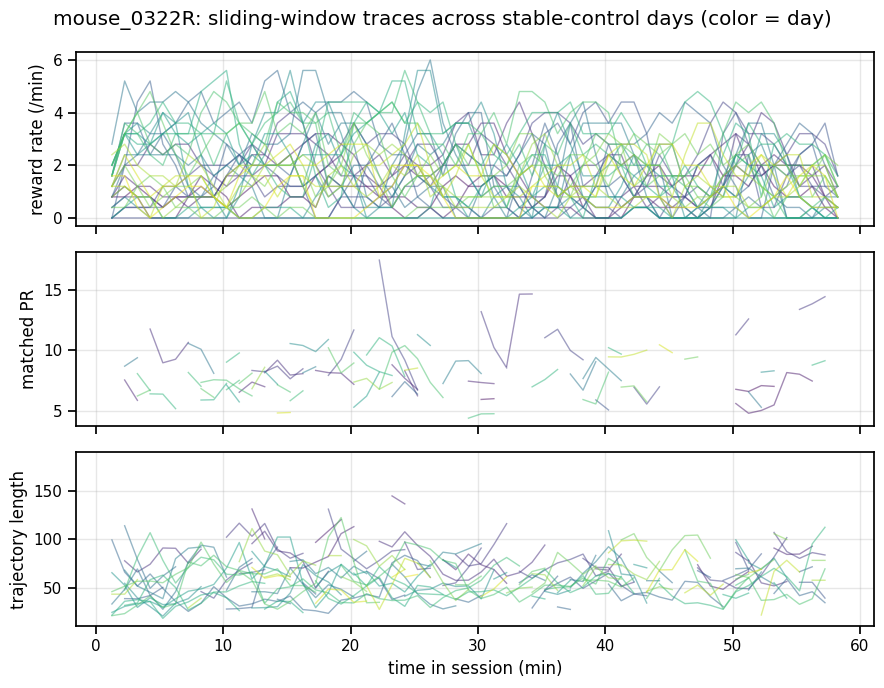

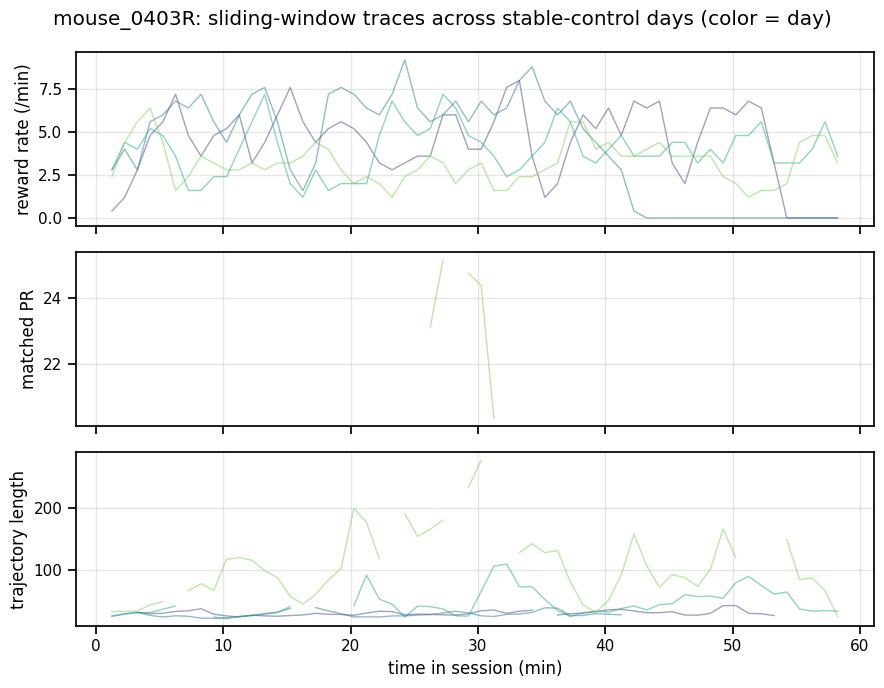

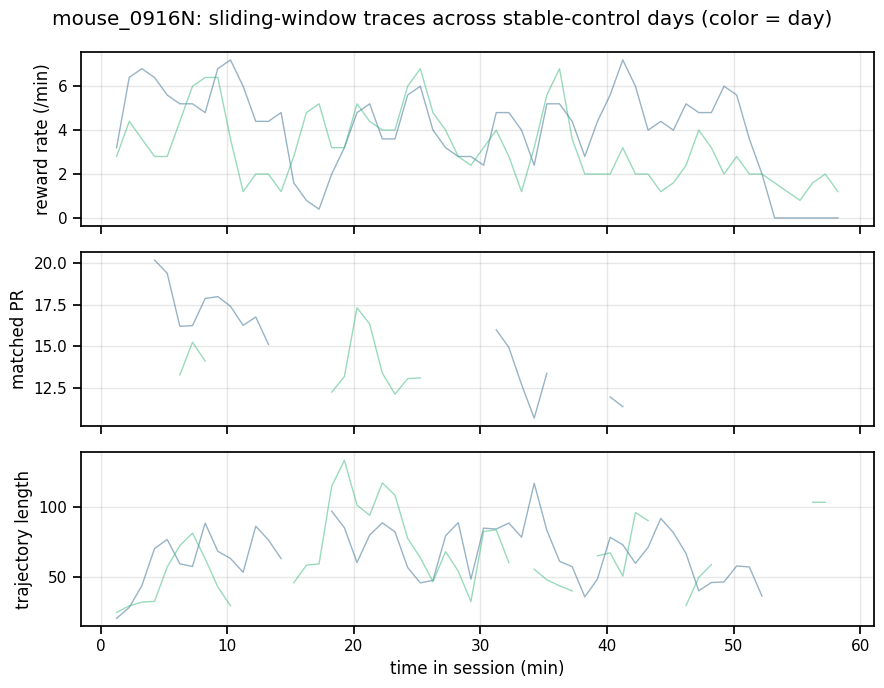

In [ ]:
trace_cols = [("reward_rate","reward rate (/min)"), ("pr_matched","matched PR"),
              ("traj_length","trajectory length")]
for m, mo in mice.items():
    sub = win_df[(win_df.mouse == m) & (win_df.phase == "stable")]
    if sub.empty: continue
    days = sorted(sub.day.unique()); pal = sns.color_palette("viridis", len(days))
    fig, axes = plt.subplots(len(trace_cols), 1, figsize=(9, 7), sharex=True)
    for ax, (col, lab) in zip(axes, trace_cols):
        for c, day in zip(pal, days):
            s = sub[sub.day == day].sort_values("center_min")
            ax.plot(s.center_min, s[col], color=c, alpha=0.5, lw=1)
        ax.set_ylabel(lab); ax.grid(alpha=0.3)
    axes[-1].set_xlabel("time in session (min)")
    fig.suptitle(f"{m}: sliding-window traces across stable-control days (color = day)")
    fig.tight_layout(); fig.savefig(mo.out / f"{m}_window_traces_stable.png", dpi=150); plt.show()

,mouse,measure,reward,n,pearson_r,pearson_p,spearman_r,spearman_p
0,mouse_0403L,pr_matched,reward_rate,751,-0.143,0.000,-0.111,0.002
1,mouse_0403L,pr_matched,reward_rate_smooth,751,-0.146,0.000,-0.118,0.001
2,mouse_0403L,traj_length,reward_rate,1849,-0.666,0.000,-0.696,0.000
3,mouse_0403L,traj_length,reward_rate_smooth,1849,-0.702,0.000,-0.741,0.000
4,mouse_0403L,traj_var,reward_rate,1849,0.528,0.000,0.640,0.000
5,mouse_0403L,traj_var,reward_rate_smooth,1849,0.577,0.000,0.688,0.000
6,mouse_0322R,pr_matched,reward_rate,225,0.177,0.008,0.188,0.005
7,mouse_0322R,pr_matched,reward_rate_smooth,225,0.132,0.048,0.145,0.030
8,mouse_0322R,traj_length,reward_rate,726,-0.379,0.000,-0.374,0.000
9,mouse_0322R,traj_length,reward_rate_smooth,726,-0.361,0.000,-0.350,0.000


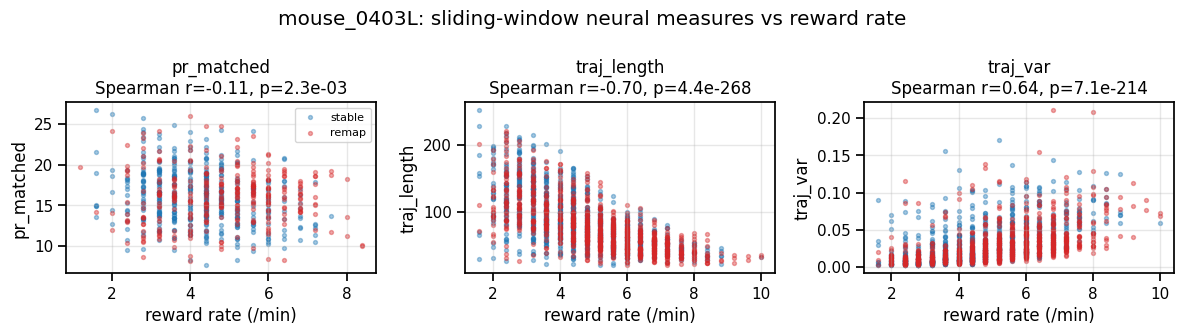

In [ ]:
neural_measures = ["pr_matched", "traj_length", "traj_var"]
corr_rows = []
for m in MICE:
    sub = win_df[win_df.mouse == m]
    for nm in neural_measures:
        for rr in ["reward_rate", "reward_rate_smooth"]:
            d = sub[[nm, rr]].dropna()
            if len(d) < 10: continue
            pr_r, pr_p = pearsonr(d[nm], d[rr]); sp_r, sp_p = spearmanr(d[nm], d[rr])
            corr_rows.append(dict(mouse=m, measure=nm, reward=rr, n=len(d),
                                  pearson_r=pr_r, pearson_p=pr_p, spearman_r=sp_r, spearman_p=sp_p))
corr_df = pd.DataFrame(corr_rows)
display(corr_df.round(3))

m = "mouse_0403L"; sub = win_df[win_df.mouse == m]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, nm in zip(axes, neural_measures):
    d = sub[[nm, "reward_rate", "phase"]].dropna()
    for ph, cc in [("stable","tab:blue"), ("remap","tab:red")]:
        dd = d[d.phase == ph]; ax.scatter(dd["reward_rate"], dd[nm], s=8, alpha=0.4, color=cc, label=ph)
    if len(d) >= 10:
        r, p = spearmanr(d[nm], d["reward_rate"]); ax.set_title(f"{nm}\nSpearman r={r:.2f}, p={p:.1e}")
    ax.set_xlabel("reward rate (/min)"); ax.set_ylabel(nm); ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
fig.suptitle(f"{m}: sliding-window neural measures vs reward rate")
fig.tight_layout(); fig.savefig(mice[m].out / f"{m}_neural_vs_reward.png", dpi=150); plt.show()

## 6 · Manifold alignment across days (stability)

`alignment_to_ref` (computed in the single pass) is the subspace alignment index — mean cos² of the
principal angles between each day's `K_PC` correct-trial subspace and the first day's subspace
(1 = identical, 0 = orthogonal). A stable exploitation manifold should stay well aligned across the
stable phase; the remapping phase may reduce alignment.

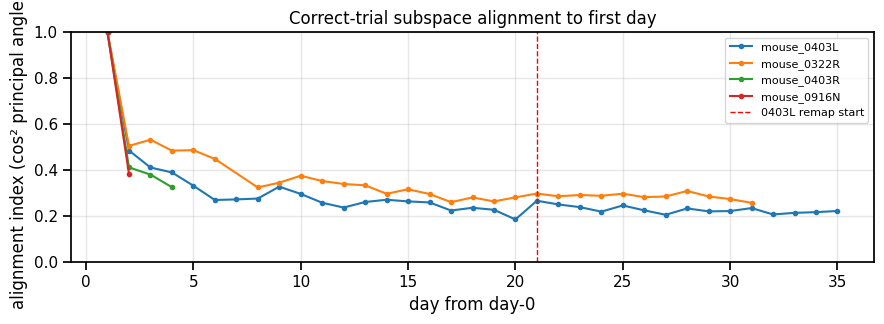

In [ ]:
fig, ax = plt.subplots(figsize=(9, 3.4))
for m in MICE:
    s = traj_df[traj_df.mouse == m].sort_values("day_from0")
    if s.empty: continue
    ax.plot(s.day_from0, s.alignment_to_ref, "o-", ms=3, label=m)
mo0 = mice["mouse_0403L"]
if mo0.remap_days:
    ax.axvline(mo0.days.index(mo0.remap_days[0]) - mo0.day0_idx, color="r", ls="--", lw=1, label="0403L remap start")
ax.set(title="Correct-trial subspace alignment to first day", xlabel="day from day-0",
       ylabel="alignment index (cos² principal angles)", ylim=(0, 1)); ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(OUTPUT_ROOT / "alignment_across_days.png", dpi=150); plt.show()

## 7 · FA-CV dimensionality (proposal's method) — optional diagnostic

Cross-validated Factor-Analysis model selection over `FA_DIMS`: `FA_FOLDS`-fold CV, fit on 75 %,
held-out log-likelihood on 25 %, averaged over folds; the effective dimensionality is the peak.
On this dataset the curve keeps rising to the grid edge (effective dim ≥ 50 even after smoothing), so
we plot the **curves** and flag edge optima rather than a single number. Set `RUN_FA_CV = True` in the
config cell and re-run Section 2 to populate this (it is the slow step, ~5–7 s/day, cached).

In [ ]:
if RUN_FA_CV and not fa_df.empty:
    display(fa_df.groupby(["mouse","condition"]).agg(best_dim_median=("best_dim","median"),
            frac_edge=("best_is_edge","mean")).reset_index())
    for m, mo in mice.items():
        for cname in FA_CONDITIONS:
            s0 = fa_df[(fa_df.mouse == m) & (fa_df.condition == cname)]
            if s0.empty: continue
            fig, ax = plt.subplots(figsize=(6.5, 3.4))
            days = sorted(s0.day.unique()); pal = sns.color_palette("viridis", len(days))
            for c, day in zip(pal, days):
                s = s0[s0.day == day].sort_values("dim"); ax.plot(s.dim, s.mean_ll, "-", color=c, alpha=0.7, lw=1)
            ax.set(title=f"{m} · {cname}: FA-CV held-out log-likelihood (color=day)",
                   xlabel="latent dimensionality", ylabel="held-out log-likelihood"); ax.grid(alpha=0.3)
            fig.tight_layout(); fig.savefig(mo.out / f"{m}_facv_{cname}.png", dpi=150); plt.show()
else:
    print("RUN_FA_CV is False (or no FA rows). Enable it in the config cell and re-run Section 2.")

RUN_FA_CV is False (or no FA rows). Enable it in the config cell and re-run Section 2.


## 8 · Remapping: intuitive vs new axis (`mouse_0403L`)

On remapping days the session starts on the **intuitive** axis (factor 2), then rotates to the **new**
axis (factor 3, identical across days). We split correct trials by axis label (never using the
unreliable weights) and compare, per remapping day: effective dimensionality (matched PR), trajectory
length, trajectory variability (per axis); plus **alignment** between the intuitive and new
correct-trial subspaces and cross **variance capture** (how much of each axis's activity lives in the
other's subspace).

In [ ]:
def compute_remap_tables(mo):
    remap_idx0 = mo.days.index(mo.remap_days[0])
    rows_axis, rows_day = [], []
    for day in tqdm(mo.remap_days, desc=f"remap {mo.name}"):
        X, trials, rew, T = preprocess_day(mo, day)
        dfrom = mo.days.index(day) - remap_idx0
        subs = {}
        for axis, fac in [("intuitive", 2.0), ("new", 3.0)]:
            ivs = na.correct_trial_intervals(trials, T, factor=fac)
            if len(ivs) < MIN_TRIALS: subs[axis] = None; continue
            Xc = na.intervals_to_matrix(X, ivs); sub = na.fit_subspace(Xc, K_PC); subs[axis] = (sub, Xc)
            pr_m, _ = na.participation_ratio_matched(Xc, MATCHED_N_SAMPLES_DAY, n_boot=MATCHED_N_BOOT)
            ts = na.trajectory_stats([sub.project(t) for t in na.intervals_to_trajectories(X, ivs)], n_resample=N_RESAMPLE)
            rows_axis.append(dict(mouse=mo.name, day=day, remap_day=dfrom, axis=axis, n_trials=len(ivs),
                                  pr_matched=pr_m, mean_length=ts.mean_length, var_per_length=ts.var_per_length))
        if subs.get("intuitive") and subs.get("new"):
            (si, Xi), (sn, Xn) = subs["intuitive"], subs["new"]
            rows_day.append(dict(mouse=mo.name, day=day, remap_day=dfrom,
                                 alignment=na.alignment_index(si, sn),
                                 mean_principal_angle=float(np.mean(na.principal_angles_deg(si, sn))),
                                 new_in_intuitive=na.variance_capture(si, Xn),
                                 intuitive_in_new=na.variance_capture(sn, Xi)))
    return pd.DataFrame(rows_axis), pd.DataFrame(rows_day)

mo = mice["mouse_0403L"]
fa_ax, fp_ax = mo.out / f"remap_axis_table_{PARAM_TAG}.csv", mo.out / f"remap_day_table_{PARAM_TAG}.csv"
if USE_CACHE and fa_ax.exists() and fp_ax.exists():
    remap_axis_df, remap_day_df = pd.read_csv(fa_ax), pd.read_csv(fp_ax)
else:
    remap_axis_df, remap_day_df = compute_remap_tables(mo)
    remap_axis_df.to_csv(fa_ax, index=False); remap_day_df.to_csv(fp_ax, index=False)
display(remap_day_df.round(3)); remap_axis_df.head()

,mouse,day,remap_day,alignment,mean_principal_angle,new_in_intuitive,intuitive_in_new
0,mouse_0403L,20230725,0,0.329,57.498,0.166,0.257
1,mouse_0403L,20230726,1,0.266,62.497,0.159,0.232
2,mouse_0403L,20230727,2,0.262,63.144,0.169,0.220
3,mouse_0403L,20230728,3,0.275,62.243,0.174,0.219
4,mouse_0403L,20230729,4,0.288,61.419,0.180,0.209
5,mouse_0403L,20230730,5,0.302,60.152,0.198,0.225
6,mouse_0403L,20230731,6,0.254,62.884,0.183,0.221
7,mouse_0403L,20230801,7,0.273,61.929,0.181,0.192
8,mouse_0403L,20230802,8,0.300,60.333,0.186,0.222
9,mouse_0403L,20230803,9,0.235,65.639,0.145,0.192


,mouse,day,remap_day,axis,n_trials,pr_matched,mean_length,var_per_length
0,mouse_0403L,20230725,0,intuitive,98,23.111366,49.701305,0.070345
1,mouse_0403L,20230725,0,new,135,55.900977,143.725652,0.006249
2,mouse_0403L,20230726,1,intuitive,87,18.710018,61.873341,0.046742
3,mouse_0403L,20230726,1,new,209,39.436382,97.297637,0.013806
4,mouse_0403L,20230727,2,intuitive,91,19.890301,83.217206,0.029351


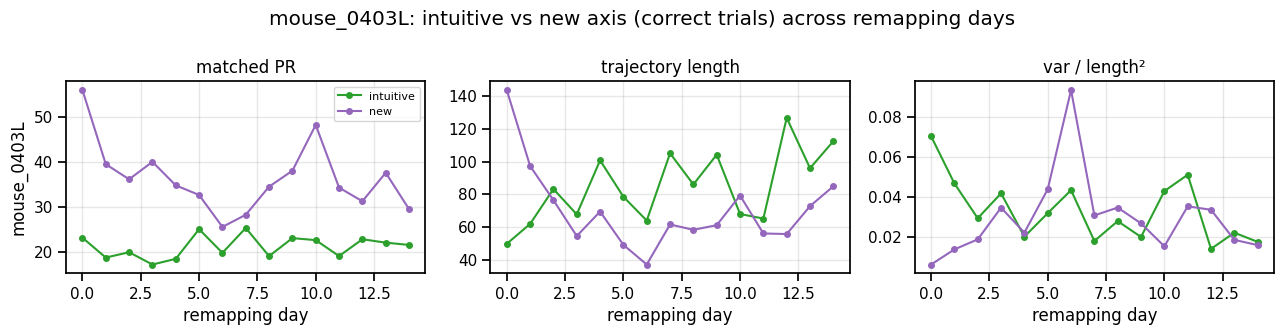

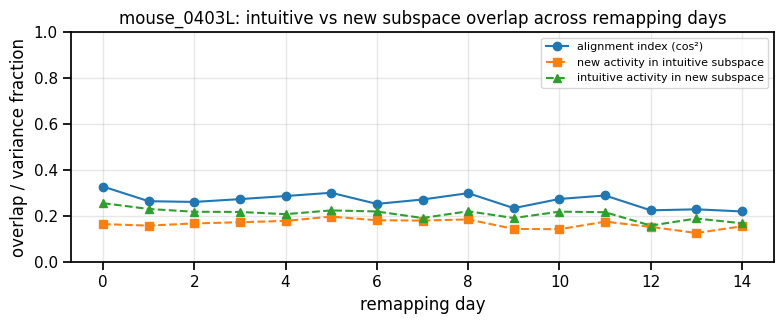

In [ ]:
mo = mice["mouse_0403L"]
axis_metrics = [("pr_matched","matched PR"), ("mean_length","trajectory length"), ("var_per_length","var / length²")]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, (col, lab) in zip(axes, axis_metrics):
    for axis, cc in [("intuitive","tab:green"), ("new","tab:purple")]:
        s = remap_axis_df[remap_axis_df.axis == axis].sort_values("remap_day")
        ax.plot(s.remap_day, s[col], "o-", ms=4, color=cc, label=axis)
    ax.set(title=lab, xlabel="remapping day"); ax.grid(alpha=0.3)
axes[0].set_ylabel("mouse_0403L"); axes[0].legend(fontsize=8)
fig.suptitle("mouse_0403L: intuitive vs new axis (correct trials) across remapping days")
fig.tight_layout(); fig.savefig(mo.out / "remap_axis_metrics.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(remap_day_df.remap_day, remap_day_df.alignment, "o-", label="alignment index (cos²)")
ax.plot(remap_day_df.remap_day, remap_day_df.new_in_intuitive, "s--", label="new activity in intuitive subspace")
ax.plot(remap_day_df.remap_day, remap_day_df.intuitive_in_new, "^--", label="intuitive activity in new subspace")
ax.set(title="mouse_0403L: intuitive vs new subspace overlap across remapping days",
       xlabel="remapping day", ylabel="overlap / variance fraction", ylim=(0, 1)); ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(mo.out / "remap_subspace_overlap.png", dpi=150); plt.show()

## 9 · One trajectory or two? (`mouse_0403L`)

Does the animal learn a **single larger trajectory** serving both axes, or maintain **two distinct
trajectories** and switch between them?

- **Two-trajectory** signature: intuitive↔new subspace overlap stays low (Section 8), the two mean
  trajectories stay separated in a common subspace, and intuitive-axis trajectory length does not grow.
- **One-trajectory** signature: overlap rises across days, the mean trajectories converge/merge, and
  the intuitive trajectory lengthens to reach the new-axis region.

Below, the intuitive and new mean correct-trial trajectories are projected into a **common** subspace
(fit on both axes combined) for an early, middle, and late remapping day.

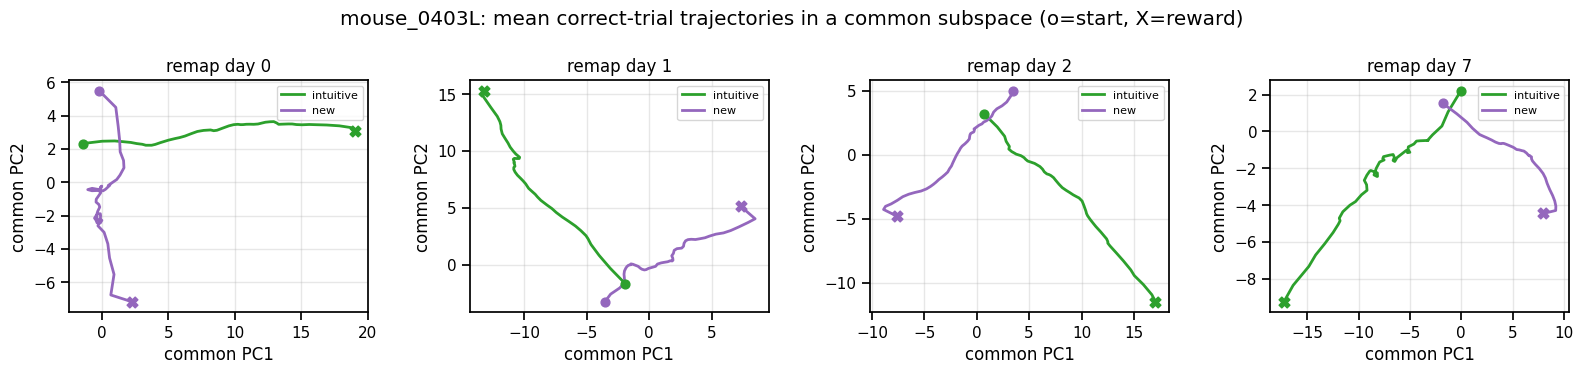

Intuitive vs new subspace overlap across remap days:


NameError: name 'remap_day_df' is not defined

In [6]:
mo = mice["mouse_0403L"]
sel = [mo.remap_days[0], mo.remap_days[1], mo.remap_days[2],mo.remap_days[len(mo.remap_days)//2]]
remap_idx0 = mo.days.index(mo.remap_days[0])
fig, axes = plt.subplots(1, len(sel), figsize=(4*len(sel), 3.8))
if len(sel) == 1: axes = [axes]
for ax, day in zip(axes, sel):
    X, trials, rew, T = preprocess_day(mo, day)
    iv_i = na.correct_trial_intervals(trials, T, factor=2.0)
    iv_n = na.correct_trial_intervals(trials, T, factor=3.0)
    common = na.fit_subspace(na.intervals_to_matrix(X, iv_i + iv_n), K_PC)
    for ivs, cc, lab in [(iv_i, "tab:green", "intuitive"), (iv_n, "tab:purple", "new")]:
        trajs = [common.project(t)[:, :2] for t in na.intervals_to_trajectories(X, ivs)]
        R = np.stack([na.resample_trajectory(t, N_RESAMPLE) for t in trajs if t.shape[0] >= 2], 0)
        mtraj = R.mean(0)
        ax.plot(mtraj[:, 0], mtraj[:, 1], color=cc, lw=2, label=lab)
        ax.scatter(*mtraj[0], color=cc, marker="o", s=40, zorder=3)
        ax.scatter(*mtraj[-1], color=cc, marker="X", s=60, zorder=3)
    ax.set(title=f"remap day {mo.days.index(day)-remap_idx0}", xlabel="common PC1", ylabel="common PC2")
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.suptitle("mouse_0403L: mean correct-trial trajectories in a common subspace (o=start, X=reward)")
fig.tight_layout(); fig.savefig(mo.out / "remap_common_trajectories.png", dpi=150); plt.show()

print("Intuitive vs new subspace overlap across remap days:")
print(remap_day_df[["remap_day","alignment","new_in_intuitive","intuitive_in_new"]].round(3).to_string(index=False))